# Objectifs d'apprentissage – Semaine 11

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les contraintes et les spécificités du DSP embarqué (temps réel, ressources limitées, quantification).
- **Identifier** les principales fonctionnalités de la bibliothèque CMSIS‑DSP pour les microcontrôleurs ARM Cortex‑M.
- **Simuler** en Python des fonctions CMSIS‑DSP courantes (filtres FIR, FFT, fonctions mathématiques).
- **Mettre en œuvre** un filtre FIR en virgule fixe (format Q) et analyser l'impact de la quantification.
- **Calculer** une FFT sur des données en virgule fixe et interpréter les résultats.
- **Proposer** une architecture logicielle pour une application DSP embarquée.
- **Préparer** une proposition de projet final intégrant du DSP sur STM32.

# 1. Introduction au DSP embarqué

Le traitement numérique du signal en environnement embarqué (microcontrôleurs, DSP, FPGA) présente des **contraintes spécifiques** :

- **Ressources limitées** : mémoire (RAM/ROM), puissance de calcul, consommation énergétique.
- **Temps réel** : les traitements doivent être effectués dans un temps imparti (latence, périodes d'échantillonnage).
- **Arithmétique en virgule fixe** : les microcontrôleurs sans FPU (Floating Point Unit) utilisent des entiers (Q format) pour les calculs.
- **Optimisation** : utilisation d'instructions SIMD, de bibliothèques optimisées (CMSIS‑DSP), et de techniques de réduction de la complexité.

## 1.1 La bibliothèque CMSIS‑DSP

CMSIS‑DSP (Cortex Microcontroller Software Interface Standard - DSP) est une bibliothèque optimisée pour les processeurs ARM Cortex‑M. Elle fournit des fonctions pour :
- Filtres FIR et IIR (en virgule flottante et fixe).
- Transformées (FFT, DCT, etc.).
- Fonctions mathématiques (sin, cos, atan2, etc.).
- Statistiques (moyenne, variance, etc.).
- Matrices et vecteurs.

Les fonctions sont disponibles en versions `_f32` (flottant 32 bits) et `_q15`/`_q31` (virgule fixe Q15/Q31).

## 1.2 Format Q (virgule fixe)

Le format Qm.n est une représentation en virgule fixe où m bits sont consacrés à la partie entière (incluant le signe) et n bits à la partie fractionnaire. Par exemple :
- **Q15** : 1 bit de signe, 15 bits fractionnaires → valeurs entre -1 et 1, précision de 1/32768.
- **Q31** : 1 bit de signe, 31 bits fractionnaires → valeurs entre -1 et 1, précision plus fine.

En Python, on peut simuler le format Q en utilisant des entiers et des opérations de décalage.

---

# 2. Simulation de fonctions CMSIS‑DSP en Python

Nous allons simuler quelques fonctions clés de CMSIS‑DSP en Python pour comprendre leur fonctionnement sans matériel. Les implémentations Python ne seront pas optimisées, mais reproduiront les résultats numériques attendus.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

## 2.1 Conversion Q15

Simulons la conversion float ↔ Q15.

In [ ]:
def float_to_q15(x):
    """Convertit un flottant (dans [-1, 1]) en entier Q15 (int16)."""
    x_sat = np.clip(x, -1.0, 1.0)
    return np.round(x_sat * 32767).astype(np.int16)

def q15_to_float(x_q):
    """Convertit un entier Q15 (int16) en flottant."""
    return x_q.astype(np.float32) / 32767.0

# Exemple
t = np.linspace(0, 0.1, 100)
signal_float = 0.9 * np.sin(2*np.pi*50*t)

signal_q15 = float_to_q15(signal_float)
signal_reconstruit = q15_to_float(signal_q15)

plt.figure(figsize=(12, 4))
plt.plot(t, signal_float, label='Flottant')
plt.plot(t, signal_reconstruit, '--', label='Q15 reconstruit')
plt.legend()
plt.grid()
plt.title('Conversion flottant ↔ Q15')
plt.show()

## 2.2 Filtre FIR en Q15 (simulation de arm_fir_q15)

Nous allons simuler un filtre FIR en utilisant des opérations Q15. La fonction `arm_fir_q15` utilise des accumulateurs en Q31 pour éviter les débordements.

In [ ]:
def fir_q15(x_q, b_q):
    """Simule un filtre FIR en Q15.
    x_q : entrée en Q15 (int16)
    b_q : coefficients en Q15 (int16)
    Retourne la sortie en Q15.
    """
    M = len(b_q)
    N = len(x_q)
    y_q = np.zeros(N, dtype=np.int16)
    # Buffer d'état (en Q15)
    state = np.zeros(M, dtype=np.int16)
    for n in range(N):
        # Mise à jour du buffer (décalage)
        state[1:] = state[:-1]
        state[0] = x_q[n]
        # Accumulateur en Q31 (32 bits) pour éviter les débordements
        acc = np.int32(0)
        for k in range(M):
            acc += np.int32(state[k]) * np.int32(b_q[k])
        # On décale de 15 pour repasser en Q15 (car produit de deux Q15 donne Q30, on ramène en Q15)
        # Attention : arrondi
        acc = (acc + (1 << 14)) >> 15
        # Saturation
        acc = np.clip(acc, -32768, 32767)
        y_q[n] = acc.astype(np.int16)
    return y_q

# Conception d'un filtre FIR passe-bas en flottant
fs = 1000
fc = 100
N_taps = 31
b_float = signal.firwin(N_taps, fc, fs=fs, window='hamming')

# Normalisation et conversion en Q15
b_float = b_float / np.max(np.abs(b_float))  # normalisation pour rester dans [-1, 1]
b_q15 = float_to_q15(b_float)

# Signal d'entrée en flottant et conversion Q15
t = np.linspace(0, 0.2, 200, endpoint=False)
x_float = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*200*t)
x_q15 = float_to_q15(x_float)

# Filtrage en Q15
y_q15 = fir_q15(x_q15, b_q15)
y_float_reconstruit = q15_to_float(y_q15)

# Filtrage en flottant pour référence
y_float_ref = signal.lfilter(b_float, 1, x_float)

# Comparaison
plt.figure(figsize=(14, 5))
plt.plot(t, y_float_ref, label='Référence flottante')
plt.plot(t, y_float_reconstruit, '--', label='Q15')
plt.legend()
plt.grid()
plt.title('Comparaison filtre FIR : flottant vs Q15')
plt.show()

err = np.max(np.abs(y_float_ref - y_float_reconstruit))
print(f"Erreur maximale : {err:.6f}")

## 2.3 FFT en Q15 (simulation de arm_rfft_q15)

La FFT en Q15 nécessite une mise à l'échelle pour éviter les débordements. Nous allons simuler une FFT sur des données Q15 et comparer avec la FFT flottante.

In [ ]:
# Simulation d'une FFT en Q15
# Pour simplifier, on utilise la FFT flottante puis on quantifie les résultats en Q15
# Dans CMSIS-DSP, la FFT est implémentée en utilisant des rotations Q15 et des additions/soustractions avec saturation.

N_fft = 128
fs = 1000
t_fft = np.arange(N_fft) / fs
x_float = 0.7 * np.sin(2*np.pi*100*t_fft) + 0.3 * np.sin(2*np.pi*200*t_fft)

# FFT flottante
X_float = fft(x_float)[:N_fft//2]

# Conversion en Q15
x_q15 = float_to_q15(x_float)

# Simulation de la FFT Q15 : on effectue la FFT en flottant puis on quantifie les résultats
# Dans la réalité, la FFT Q15 utilise des étapes de mise à l'échelle.
X_q15_float = fft(q15_to_float(x_q15))[:N_fft//2]
# On quantifie les résultats en Q15 pour simuler la sortie de arm_rfft_q15
# La sortie de arm_rfft_q15 est généralement en Q15 pour la partie réelle et imaginaire.
X_q15_real = float_to_q15(np.real(X_q15_float))
X_q15_imag = float_to_q15(np.imag(X_q15_float))
X_q15 = q15_to_float(X_q15_real) + 1j * q15_to_float(X_q15_imag)

freqs = fftfreq(N_fft, 1/fs)[:N_fft//2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.stem(freqs, np.abs(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.abs(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15 simulé')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(freqs, np.angle(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.angle(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

print("La version Q15 introduit une légère dégradation due à la quantification.")

## 2.4 Fonctions mathématiques (sin, cos, atan2) en Q15

CMSIS‑DSP fournit des tables de recherche pour les fonctions trigonométriques en Q15. Simulons un calcul de sinus en Q15 à l'aide d'une table.

In [ ]:
# Table de sinus Q15 pour 360 degrés (ou 2*pi radians)
# En pratique, la table est stockée dans la mémoire du microcontrôleur.
def sin_q15(angle_q15):
    """Simule arm_sin_q15 : angle en Q15 (0 correspond à 0 rad, 32767 correspond à 2*pi)."""
    # angle_q15 est un entier int16 entre 0 et 32767 représentant 0 à 2*pi
    # On utilise une interpolation linéaire sur une table de 256 points
    n_points = 256
    table = np.sin(2*np.pi * np.arange(n_points) / n_points)
    # Convertir angle_q15 en index 0..n_points-1
    idx = (angle_q15 * n_points) // 32768
    idx = np.clip(idx, 0, n_points-1)
    # Interpolation linéaire
    frac = (angle_q15 * n_points) % 32768 / 32768.0
    val = (1-frac) * table[idx] + frac * table[(idx+1) % n_points]
    return float_to_q15(val)

# Test
angles = np.linspace(0, 2*np.pi, 100)
sin_float = np.sin(angles)
sin_q15_vals = np.array([sin_q15(float_to_q15(angle/(2*np.pi))) for angle in angles])
sin_reconst = q15_to_float(sin_q15_vals)

plt.plot(angles, sin_float, label='sin flottant')
plt.plot(angles, sin_reconst, '--', label='sin Q15 (table)')
plt.legend()
plt.grid()
plt.show()

# 3. Atelier : Mise en œuvre d'une application DSP embarquée

Nous allons simuler une application complète : un filtre anti-repliement (passe-bas) suivi d'une FFT pour analyser un signal, en utilisant des fonctions en virgule fixe. L'architecture est typique d'un système embarqué temps réel : acquisition (ADC), filtrage, FFT, puis communication ou affichage.

In [ ]:
# Paramètres système
fs = 1000
N_samples = 128
t = np.arange(N_samples) / fs

# Signal d'entrée simulé (mélange de fréquences)
x_float = np.sin(2*np.pi*80*t) + 0.5*np.sin(2*np.pi*250*t) + 0.1*np.random.randn(N_samples)

# 1. Filtre anti-repliement (passe-bas en Q15)
# Conception du filtre en flottant
fc = 150
b_float = signal.firwin(31, fc, fs=fs, window='hamming')
b_float = b_float / np.max(np.abs(b_float))
b_q15 = float_to_q15(b_float)

# Conversion entrée en Q15
x_q15 = float_to_q15(x_float)

# Filtrage
y_q15 = fir_q15(x_q15, b_q15)
y_float = q15_to_float(y_q15)

# 2. FFT en Q15 sur le signal filtré
# (simulée comme précédemment)
X_q15_real = float_to_q15(np.real(fft(y_float)[:N_samples//2]))
X_q15_imag = float_to_q15(np.imag(fft(y_float)[:N_samples//2]))
X_q15 = q15_to_float(X_q15_real) + 1j*q15_to_float(X_q15_imag)

freqs = fftfreq(N_samples, 1/fs)[:N_samples//2]

# Visualisation
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(t, x_float)
plt.title('Signal d\'entrée (avec bruit)')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(t, y_float)
plt.title('Signal filtré (passe-bas)')
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(freqs, np.abs(fft(x_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre avant filtrage')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs, np.abs(fft(y_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre après filtrage (Q15)')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.tight_layout()
plt.show()

# Bilan des ressources simulées
print(f"Taille du filtre : {len(b_q15)} coefficients en Q15")
print(f"Nombre d'échantillons FFT : {N_samples}")
print("En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.")

# 4. Exercices – Semaine 11

## Exercice 1 – Filtre RII en Q15

1. Concevoir un filtre RII Butterworth passe-bas d'ordre 4 avec fc=100 Hz, fs=1000 Hz.
2. Convertir les coefficients en Q15 (normalisation puis quantification).
3. Implémenter une fonction `iir_q15` simulant un filtre RII en Q15 (structure directe II) en utilisant un accumulateur Q31.
4. Tester sur un signal bruité et comparer avec la version flottante.
5. Discuter de la stabilité : que se passe-t-il si l'ordre est trop élevé en Q15 ?

**Code** :

Correction exercice 1

**5. Stabilité en Q15 quand l'ordre est trop élevé**

- **Plage des coefficients** : en forme directe, les $a_k$ croissent avec l'ordre (max$|a_k|$ = 2,4 à l'ordre 4, 5,7 à l'ordre 6, 13 à l'ordre 8 pour $f_c=100$ Hz). Ils sortent de $[-1,1[$ : il faut un format Q3.12 ou plus, donc moins de bits de précision.
- **Sensibilité des pôles** : les racines d'un polynôme d'ordre élevé sont très sensibles à l'erreur sur ses coefficients, surtout quand $f_c \ll f_s$ (pôles proches de $z=1$). Pour $f_c = 20$ Hz et $f_s = 1$ kHz :
  - ordre 8 : pôle max 0,976 en flottant, mais **1,255 après quantification** Q12, donc **filtre instable** ;
  - ordre 4 : 0,953 en flottant, 0,998 après quantification, à la limite de l'instabilité.
- **Débordements internes** : en forme directe II, l'état $w[n]$ a un gain pouvant atteindre 13,9 (ici) : il faut l'atténuer, ce qui coûte des bits de précision (bruit de quantification plus grand).
- **Solution** : décomposer en **sections d'ordre 2 (biquads)** en cascade (`arm_biquad_cascade_df1_q15`) : chaque pôle ne dépend que de 2 coefficients de faible amplitude ($|{\cdot}|<4$, Q2.13). Le même filtre d'ordre 8 reste stable (pôle max 0,976).

Gain interne = 13.936749375348976 p = 4
b_q = [ 316 1265 1897 1265  316]
a_q = [ 4096 -9706  9478 -4320   768]
Erreur max = 0.000605570920752585
SNR = 58.827505060602896 dB


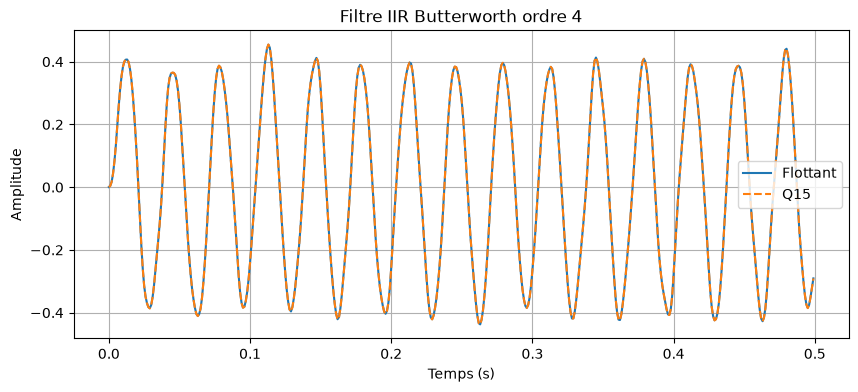

Ordre 4 | Pôles flottants : 0.953 | Pôles quantifiés : 0.998
Ordre 8 | Pôles flottants : 0.976 | Pôles quantifiés : 1.255
Pôle max biquads = 0.976


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# 1. Conception du filtre Butterworth
fs, fc, order = 1000, 100, 4
b, a = signal.butter(order, fc, fs=fs)

# 2. Normalisation et quantification Q12
FRAC = 12
_, H = signal.freqz([1.0], a, worN=4096)
g = np.max(np.abs(H))
p = max(0, int(np.ceil(np.log2(g))))

b_q = np.round(b * 2**p * 2**FRAC).astype(np.int64)
a_q = np.round(a * 2**FRAC).astype(np.int64)

print("Gain interne =", g, "p =", p)
print("b_q =", b_q)
print("a_q =", a_q)

# 3. Filtre IIR Direct Form II en Q15
def iir_q15(x_q, b_q, a_q, frac=12, p=0):
    N = len(x_q)
    w = np.zeros(max(len(a_q), len(b_q))-1, dtype=np.int64)
    y_q = np.zeros(N, dtype=np.int16)
    rnd = 1 << (frac-1)

    for n in range(N):
        acc = (int(x_q[n]) << frac) >> p

        for k in range(1, len(a_q)):
            acc -= int(a_q[k]) * w[k-1]

        w0 = np.clip((acc+rnd) >> frac, -32768, 32767)

        acc = int(b_q[0]) * w0
        for k in range(1, len(b_q)):
            acc += int(b_q[k]) * w[k-1]

        y_q[n] = np.clip((acc+rnd) >> frac, -32768, 32767)

        w[1:] = w[:-1]
        w[0] = w0

    return y_q

# 4. Signal d'entrée
np.random.seed(0)
t = np.arange(500)/fs
x = (0.4*np.sin(2*np.pi*30*t)
     + 0.2*np.sin(2*np.pi*300*t)
     + 0.05*np.random.randn(500))

x_q = np.clip(np.round(x*32768), -32768, 32767).astype(np.int16)

# 5. Filtrage Q15 et flottant
y_q = iir_q15(x_q, b_q, a_q, FRAC, p)
y = y_q.astype(float)/32768
y_ref = signal.lfilter(b, a, x_q.astype(float)/32768)

# 6. Erreur et SNR
err = y-y_ref
print("Erreur max =", np.max(np.abs(err)))
print("SNR =", 10*np.log10(np.var(y_ref)/np.var(err)), "dB")

# 7. Affichage
plt.figure(figsize=(10,4))
plt.plot(t, y_ref, label="Flottant")
plt.plot(t, y, '--', label="Q15")
plt.title("Filtre IIR Butterworth ordre 4")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# 8. Etude de stabilité
for ordre in (4, 8):
    bb, aa = signal.butter(ordre, 20, fs=fs)
    aa_q = np.round(aa*2**FRAC)/2**FRAC
    print("Ordre", ordre,
          "| Pôles flottants :", round(max(abs(np.roots(aa))), 3),
          "| Pôles quantifiés :", round(max(abs(np.roots(aa_q))), 3))

# 9. Cascade de biquads
sos = signal.butter(8, 20, fs=fs, output='sos')
sos_q = np.round(sos*2**13)/2**13

print("Pôle max biquads =", round(
    max(max(abs(np.roots(s[3:]))) for s in sos_q), 3))


## Exercice 2 – FFT en Q15 et fenêtrage

1. Générer un signal composé de deux sinusoïdes de fréquences 120 Hz et 130 Hz, fs=1000 Hz, N=64.
2. Appliquer une fenêtre de Hamming en Q15 (convertir la fenêtre en Q15).
3. Calculer la FFT en Q15 (simulée) et tracer le spectre.
4. Comparer la résolution spectrale avec et sans fenêtre.

**Code** :

Correction exercice 2

**4. Résolution spectrale avec et sans fenêtre**

- Pas de la FFT : $\Delta f = f_s/N = 1000/64 = 15{,}6$ Hz, alors que les deux sinusoïdes sont séparées de **10 Hz** $<\Delta f$.
- **Sans fenêtre (rectangulaire)** : lobe principal étroit ($\approx 2\Delta f$ de large), mais lobes secondaires élevés (−13 dB) qui fuient sur les bins voisins. Les deux raies se confondent en un seul pic à 125 Hz.
- **Avec Hamming** : lobes secondaires bien plus faibles (≈ −43 dB), mais lobe principal **2 fois plus large** ($\approx 4\Delta f$). La résolution est **moins bonne** : un seul pic à 125 Hz.
- **Conclusion** : une fenêtre améliore la *dynamique* (détecter une raie faible près d'une forte), pas la *résolution*. Pour séparer 120 et 130 Hz il faut allonger l'observation : $N \gtrsim f_s/10 = 100$ (donc 128) en rectangulaire, $N \gtrsim 200$ (donc 256) avec Hamming. Le zero-padding ne sépare pas les raies, il ne fait qu'interpoler le spectre.
- **Q15** : la mise à l'échelle $1/2$ par étage évite les débordements (sortie = FFT/N), au prix d'un plancher de bruit plus élevé (on perd $\log_2 N$ bits de dynamique). L'erreur reste ici négligeable (≈ 3·10⁻³ pour un pic de 11,5).

Erreur FFT Q15 vs flottant (rect) : 0.003 (pic = 11.5)
rectangulaire : pics à [125.] Hz
Hamming       : pics à [125.] Hz


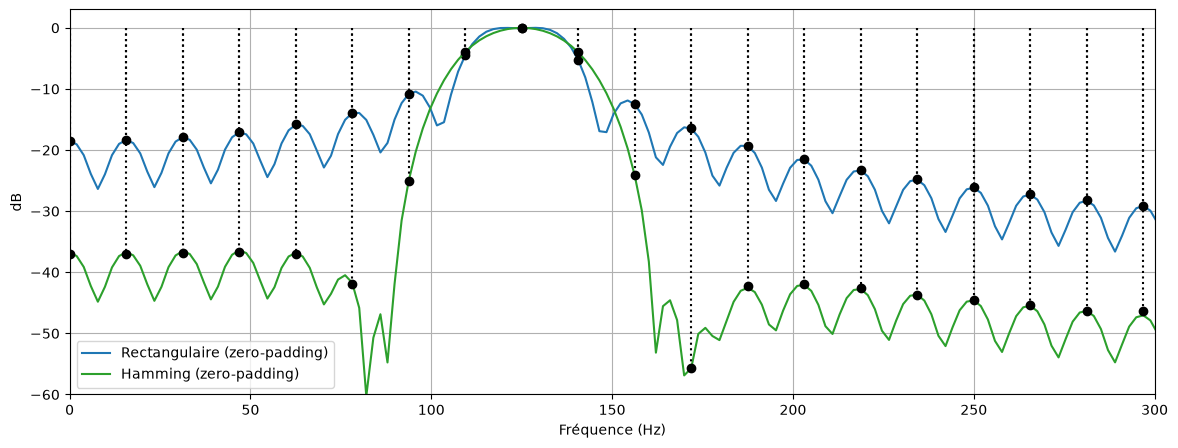

In [5]:
from scipy.signal import find_peaks

def fft_q15(x_q):
    """FFT radix-2 DIT en Q15, mise à l'échelle 1/2 par étage (comme CMSIS) => sortie = FFT/N."""
    N = len(x_q); L = int(np.log2(N))
    idx = np.array([int(format(i, f'0{L}b')[::-1], 2) for i in range(N)])   # bit-reversal
    re = x_q.astype(np.int64)[idx]; im = np.zeros(N, dtype=np.int64)
    k = np.arange(N // 2)
    wr = float_to_q15(np.cos(2*np.pi*k/N)).astype(np.int64)                  # twiddles Q15
    wi = float_to_q15(-np.sin(2*np.pi*k/N)).astype(np.int64)
    size = 2
    while size <= N:
        half, step = size // 2, N // size
        for s in range(0, N, size):
            for j in range(half):
                a_, b_ = s + j, s + j + half
                c, d = wr[j*step], wi[j*step]
                tr = (re[b_]*c - im[b_]*d + (1 << 14)) >> 15
                ti = (re[b_]*d + im[b_]*c + (1 << 14)) >> 15
                re[b_], im[b_] = (re[a_] - tr) >> 1, (im[a_] - ti) >> 1
                re[a_], im[a_] = (re[a_] + tr) >> 1, (im[a_] + ti) >> 1
        size *= 2
    return np.clip(re, -32768, 32767).astype(np.int16), np.clip(im, -32768, 32767).astype(np.int16)

fs, N = 1000, 64
t = np.arange(N) / fs
x = 0.4*np.sin(2*np.pi*120*t) + 0.4*np.sin(2*np.pi*130*t)       # amplitude totale <= 0.8 (pas de débordement)
x_q = float_to_q15(x)

# Fenêtre de Hamming en Q15, puis produit Q15 x Q15 -> Q15 (avec arrondi)
w_q = float_to_q15(np.hamming(N))
xw_q = ((x_q.astype(np.int32) * w_q.astype(np.int32) + (1 << 14)) >> 15).astype(np.int16)

def spectre_q15(sig_q):
    re, im = fft_q15(sig_q)
    return (q15_to_float(re) + 1j*q15_to_float(im)) * len(sig_q)   # on remet l'échelle (x N)

X_rect, X_ham = spectre_q15(x_q), spectre_q15(xw_q)
err = np.max(np.abs(X_rect - np.fft.fft(q15_to_float(x_q))))
print(f"Erreur FFT Q15 vs flottant (rect) : {err:.3f} (pic = {np.max(np.abs(X_rect)):.1f})")

f = np.arange(N) * fs / N
for nom, X in (('rectangulaire', X_rect), ('Hamming', X_ham)):
    pics, _ = find_peaks(np.abs(X[:N//2]), height=0.3*np.max(np.abs(X)))
    print(f"{nom:14s}: pics à {f[pics]} Hz")

# Spectres (échelle dB) + version flottante zero-padding x8 pour voir les lobes
plt.figure(figsize=(14, 5))
for nom, X, win in (('Rectangulaire', X_rect, np.ones(N)), ('Hamming', X_ham, np.hamming(N))):
    Xz = np.abs(np.fft.fft(x * win, 8*N))[:4*N]
    plt.plot(np.arange(4*N) * fs / (8*N), 20*np.log10(Xz/np.max(Xz) + 1e-6), label=f'{nom} (zero-padding)')
    plt.stem(f[:N//2], 20*np.log10(np.abs(X[:N//2])/np.max(np.abs(X)) + 1e-6),
             basefmt=' ', linefmt='k:', markerfmt='ko')
plt.ylim(-60, 3); plt.xlim(0, 300); plt.xlabel('Fréquence (Hz)'); plt.ylabel('dB')
plt.legend(); plt.grid(); plt.show()


## Exercice 3 – Estimation de la consommation mémoire

Pour une application DSP embarquée, on doit estimer la mémoire nécessaire.

1. Un filtre FIR à 64 coefficients en Q15 (int16) est utilisé. Calculer la mémoire pour les coefficients, l'état (buffer circulaire), et le code si nécessaire.
2. Une FFT de 256 points en Q15 nécessite des tables de twiddle factors (rotations). Estimer la mémoire pour ces tables.
3. Proposer une optimisation pour réduire la mémoire (par exemple, utiliser des coefficients symétriques pour le FIR).

**Réponse** :
- Coefficients : 64 * 2 octets = 128 octets.
- Buffer d'état : 64 * 2 = 128 octets.
- Tables FFT (twiddle) : pour N=256, environ N/2 * 2 = 256 octets en Q15.
- Total : environ 512 octets, plus le code. On peut réduire en utilisant la symétrie pour le FIR (coefficients symétriques) ce qui permet de stocker la moitié des coefficients et d'utiliser une structure optimisée.

Correction exercice 3

**1. FIR 64 coefficients Q15**
- Coefficients : $64 \times 2 = 128$ octets (en flash).
- État : 128 octets au minimum (buffer circulaire). Avec `arm_fir_q15` : $(64 + \text{blockSize} - 1)\times 2$ octets, soit 190 octets pour un bloc de 32.
- Code : de l'ordre de quelques centaines d'octets (à lire dans le fichier `.map`).

**2. FFT 256 points Q15**
- Twiddles : $N/2 = 128$ complexes $\times 2$ valeurs $\times 2$ octets = **512 octets** au minimum. Les tables CMSIS stockent $2N$ valeurs, soit **1024 octets**, plus la table de bit-reversal.
- Buffers : entrée réelle $256\times2 = 512$ octets, sortie `arm_rfft_q15` $2N = 512$ valeurs $= 1024$ octets.

**Total** : ≈ 128 + 128 + 512 (twiddles) + 1536 (buffers) ≈ **2,3 Ko** (jusqu'à ≈ 2,9 Ko avec les tables CMSIS et le bloc FIR), et non 512 octets : l'erreur du cours vient de l'oubli de la partie imaginaire des twiddles et des buffers FFT.

**3. Optimisations**
- **FIR symétrique** (phase linéaire) : on ne stocke que 32 coefficients (−64 octets) et on fait 32 multiplications au lieu de 64 (pré-addition de $x[n-k] + x[n-63+k]$).
- **Twiddles** : par symétrie quart d'onde, on ne stocke que $N/4+1 = 65$ valeurs de sinus (130 octets) et on retrouve le cosinus par $\cos\theta = \sin(\theta+\pi/2)$ : gain d'un facteur 4 à 8 sur la table.
- **FFT en place** et buffers partagés entre le FIR et la FFT.

## Exercice 4 – Proposition de projet final

Rédiger une proposition de projet intégrant du DSP sur STM32 avec CMSIS‑DSP. La proposition doit inclure :
- Objectif du projet (ex : analyse de signaux ECG, traitement audio, contrôle moteur).
- Spécifications techniques (fréquence d'échantillonnage, nombre de canaux, type de traitement).
- Choix des algorithmes (filtres, FFT, etc.) et justification.
- Estimation des ressources (temps de calcul, mémoire).
- Plan de développement.

**Rédiger la proposition dans une cellule Markdown.**

Correction exercice 4

## 1. Objectif
Acquérir un ECG mono-dérivation, supprimer les perturbations (dérive de la ligne de base, secteur 50 Hz, bruit musculaire) et détecter les complexes QRS pour afficher la fréquence cardiaque en temps réel.

## 2. Spécifications techniques
- Microcontrôleur : STM32F411 (Cortex-M4F, 100 MHz, 128 Ko de RAM, FPU).
- Acquisition : ADC 12 bits déclenché par timer, DMA double buffer, $f_s = 500$ Hz, 1 canal (via amplificateur d'instrumentation type AD8232).
- Bande utile : 0,5 – 40 Hz. Sortie : fréquence cardiaque (bpm) via UART/écran, et signal filtré.

## 3. Algorithmes et justification
| Étape | Algorithme CMSIS-DSP | Justification |
|---|---|---|
| Passe-haut 0,5 Hz | biquad IIR (`arm_biquad_cascade_df1_f32`) | supprime la dérive avec peu de calcul |
| Coupe-bande 50 Hz | biquad IIR | élimine le secteur sans trop déformer le QRS |
| Passe-bas 40 Hz | FIR 31 coefficients (`arm_fir_q15`) | phase linéaire, donc pas de déformation du QRS |
| Détection QRS | dérivée, mise au carré, moyenneur glissant (~150 ms), seuil adaptatif (type Pan-Tompkins) | méthode classique, peu coûteuse |
| Qualité du signal | FFT 256 points (`arm_rfft_q15`) toutes les secondes | mesure du résidu 50 Hz |

Les filtres IIR sont implémentés en `f32` (FPU disponible, stabilité facile). Une variante Q15 sera comparée pour étudier l'impact de la quantification.

## 4. Estimation des ressources
- **Temps** : budget = $100\,\text{MHz}/500\,\text{Hz} = 200\,000$ cycles par échantillon. Chaîne de traitement estimée à quelques centaines de cycles par échantillon, FFT ≈ 10⁴ cycles toutes les 500 échantillons, soit une charge CPU < 5 %. À mesurer avec le compteur de cycles `DWT->CYCCNT`.
- **Mémoire** : FIR (62 octets de coefficients + état), biquads (quelques dizaines d'octets), FFT 256 pts (≈ 2 Ko), buffers DMA 2 × 128 échantillons : au total **< 5 Ko de RAM**.

## 5. Plan de développement
1. Semaine 1 : prototype Python (filtres + détection QRS) sur la base MIT-BIH.
2. Semaine 2 : acquisition ADC/DMA/timer sur STM32, vérification de $f_s$.
3. Semaine 3 : intégration des filtres CMSIS-DSP, comparaison avec Python.
4. Semaine 4 : détection QRS et calcul des bpm.
5. Semaine 5 : version Q15, mesure des cycles et de la mémoire.
6. Semaine 6 : tests (signaux simulés), rapport et démonstration.

## Exercice 5 – Simulation d'une application temps réel

On souhaite simuler un traitement temps réel sur un microcontrôleur. On considère un buffer circulaire de 128 échantillons, un filtre FIR de 31 coefficients, et une FFT de 128 points.

1. Écrire un code Python qui simule le traitement en continu : chaque itération, on ajoute un nouvel échantillon, on met à jour le buffer, on applique le filtre et on calcule la FFT sur les 128 derniers échantillons.
2. Mesurer le temps d'exécution de chaque étape (utiliser `time.perf_counter`).
3. Estimer si un Cortex-M4 à 100 MHz peut respecter une période d'échantillonnage de 1 ms.
4. Proposer des optimisations (ex : utiliser la FFT uniquement tous les N échantillons).

**Code** :

In [6]:
import time

BUF, M, FFT_EVERY = 128, 31, 1          # FFT_EVERY = 1 : FFT à chaque échantillon (pire cas)
fs = 1000
b = signal.firwin(M, 100, fs=fs, window='hamming')
win = np.hamming(BUF)

buf = np.zeros(BUF); idx = 0              # buffer circulaire (idx = prochaine position d'écriture)
t_buf, t_fir, t_fft = [], [], []

for n in range(2000):
    x_new = np.sin(2*np.pi*50*n/fs) + 0.5*np.sin(2*np.pi*200*n/fs) + 0.1*np.random.randn()

    t0 = time.perf_counter()
    buf[idx] = x_new; idx = (idx + 1) % BUF                       # 1) mise à jour du buffer circulaire
    t1 = time.perf_counter()
    y = np.dot(b, buf[(idx - 1 - np.arange(M)) % BUF])            # 2) FIR sur les M derniers (récent -> ancien)
    t2 = time.perf_counter()
    t_buf.append(t1 - t0); t_fir.append(t2 - t1)

    if n >= BUF and n % FFT_EVERY == 0:                           # 3) FFT sur les 128 derniers
        X = np.fft.rfft(np.roll(buf, -idx) * win)                 # remise dans l'ordre chronologique
        t_fft.append(time.perf_counter() - t2)

for nom, tt in (('buffer', t_buf), ('FIR', t_fir), ('FFT', t_fft)):
    print(f"{nom:7s}: moyenne {np.mean(tt)*1e6:7.1f} µs | max {np.max(tt)*1e6:8.1f} µs")

buffer : moyenne     0.4 µs | max      7.3 µs
FIR    : moyenne     6.8 µs | max   2846.8 µs
FFT    : moyenne    19.9 µs | max    206.9 µs


Correction exercice 5

**3. Faisabilité sur Cortex-M4 à 100 MHz, $T_e = 1$ ms**

Budget : $100\,\text{MHz} \times 1\,\text{ms} = 100\,000$ cycles par échantillon. Estimation avec CMSIS-DSP (à confirmer par mesure avec `DWT->CYCCNT`) :
- mise à jour du buffer : quelques cycles ;
- FIR 31 coefficients Q15 : ≈ 50 à 100 cycles (instructions MAC dual `SMLAD`) ;
- FFT réelle 128 points Q15 : ≈ 5 000 à 15 000 cycles.

Même avec une FFT à **chaque échantillon**, on est à environ 10 à 15 % du budget : le traitement **respecte largement** la période de 1 ms. Les temps Python ne sont pas transposables : ils ne servent qu'à comparer les étapes entre elles.

**4. Optimisations**
- Calculer la FFT seulement tous les $N/2$ ou $N/4$ échantillons (recouvrement 50 ou 75 %) : charge divisée par 64 ou 32.
- Traiter par **blocs** (DMA + double buffer) plutôt qu'échantillon par échantillon, ce qui réduit l'overhead des appels.
- Buffer circulaire à taille puissance de 2 (indice par masque `& 127`) pour éviter les copies de type `np.roll`.
- FIR symétrique (moitié moins de multiplications) et fenêtre de Hamming précalculée en Q15.
- Utiliser `arm_rfft_q15` plutôt qu'une FFT complexe (environ 2 fois moins de calcul pour un signal réel).

# 5. Livrable Semaine 11

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---